# Why did CatBoost not beat the median baseline? Train-only diagnostics

Notebook `02_delay_regression_catboost.ipynb` found no improvement over the Train-median baseline on pooled validation (MAE 4.53 vs 4.41 days; 95% interval [−0.02, +0.26]). This notebook tests two explanations, declared in `docs/machine_learning/experiment_protocol.md` (*Diagnostic amendment*) before it was run:

- **H1:** the 21 purchase-time predictors carry little transferable information about delay length.
- **H2:** state-day weather values act as a *date fingerprint*, so the model memorises period-specific delay levels that do not recur.

**Only Train late orders are used.** Validation A/B and Test are not loaded. Nothing here changes the retained baseline decision or selects a model for later use.

| Fold | Fit: purchased **and delivered** before | Score: purchased in |
|---|---|---|
| 1 | 2017-07-01 | [2017-07-01, 2017-10-01) |
| 2 | 2017-10-01 | [2017-10-01, 2018-01-01) |
| 3 | 2018-01-01 | [2018-01-01, 2018-03-02) |

Configurations per fold: `MedianBaseline`, `CatBoost21` (all predictors) and `CatBoost15_noWeather` (six weather predictors removed). CatBoost settings match `CatBoostDelayRegressor`.

## 1. Environment and inputs

In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

current = Path.cwd().resolve()
ROOT = next((p for p in [current, *current.parents]
             if (p / 'docs/predictor_list.csv').is_file() and (p / 'notebooks').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the project repository.')

INPUTS = ['data/processed/research_data_weather_price_holiday_assume_utc.csv',
          'docs/predictor_list.csv', 'data/ml_preparation/split_manifest.csv']
TABLES = ROOT / 'outputs/tables/delay_prediction/regression_train_diagnostics'
FIGURES = ROOT / 'outputs/figures/delay_prediction/regression_train_diagnostics'
for path in (TABLES, FIGURES):
    path.mkdir(parents=True, exist_ok=True)

SEED, N_BOOT = 42, 2000
FOLDS = [('fold_1', '2017-07-01', '2017-10-01'),
         ('fold_2', '2017-10-01', '2018-01-01'),
         ('fold_3', '2018-01-01', '2018-03-02')]
CONFIGS = ['MedianBaseline', 'CatBoost21', 'CatBoost15_noWeather']
COLORS = dict(zip(CONFIGS, ['#257de0', '#f47230', '#00b894']))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.edgecolor': '#666666',
                     'xtick.color': '#666666', 'ytick.color': '#666666'})

predictors = pd.read_csv(ROOT / INPUTS[1])
features = predictors.feature.tolist()
weather = predictors.loc[predictors.group.eq('F3'), 'feature'].tolist()
assert len(features) == 21 and len(weather) == 6
cat = ['customer_state', 'purchase_weekday']
FEATURE_SETS = {'CatBoost21': features,
                'CatBoost15_noWeather': [f for f in features if f not in weather]}
print('Weather predictors removed in CatBoost15_noWeather:', weather)

Weather predictors removed in CatBoost15_noWeather: ['destination_rain_state_mean_mm', 'origin_rain_state_mean_mm', 'destination_humidity_state_mean_pct', 'origin_humidity_state_mean_pct', 'destination_air_temp_state_mean_c', 'origin_air_temp_state_mean_c']


## 2. Load Train orders

In [2]:
columns = ['order_id', 'is_late', 'delivery_delay_days', 'order_delivered_customer_date',
           'order_estimated_delivery_date', *features]
source = pd.read_csv(ROOT / INPUTS[0], usecols=columns, dtype={'order_id': str})
manifest = pd.read_csv(ROOT / INPUTS[2], dtype={'order_id': str})
assert source.order_id.is_unique and manifest.order_id.is_unique
ids = manifest.loc[manifest.split.eq('train'), ['order_id', 'purchase_time']]
train_all = ids.merge(source, on='order_id', how='left', validate='one_to_one')
assert len(train_all) == 57449 and train_all.is_late.isin([0, 1]).all()

train_all['purchase'] = pd.to_datetime(train_all.purchase_time)
train_all['delivered'] = pd.to_datetime(train_all.order_delivered_customer_date)
train_all['purchase_date'] = train_all.purchase.dt.normalize()
for c in cat:
    train_all[c] = train_all[c].map(lambda v: str(v) if pd.notna(v) else np.nan)

late = train_all.loc[train_all.is_late.eq(1)].copy()
recomputed = (late.delivered.dt.normalize()
              - pd.to_datetime(late.order_estimated_delivery_date).dt.normalize()).dt.days
np.testing.assert_array_equal(recomputed.to_numpy(), late.delivery_delay_days.to_numpy())
late['y'] = late.delivery_delay_days.astype(int)
assert len(late) == 3720 and late.y.ge(1).all()
print('Train orders:', len(train_all), '| Train late orders:', len(late))

Train orders: 57449 | Train late orders: 3720


## 3. Is weather a date fingerprint? (no target used)

For every Train order with complete weather, the six weather values are paired with the customer state. If almost every such vector occurs on only one purchase date, a tree model can use weather to recognise specific days and their delay levels.

In [3]:
def fingerprint(frame, cols, label):
    complete = frame.dropna(subset=cols)
    key = complete[['customer_state', *cols]].round(6).astype(str).agg('|'.join, axis=1)
    dates_per_key = complete.groupby(key).purchase_date.nunique()
    one_day = dates_per_key.eq(1)
    return {'predictors': label, 'orders_with_complete_values': len(complete),
            'distinct_vectors': len(dates_per_key),
            'distinct_state_purchase_dates': complete.groupby(['customer_state', 'purchase_date']).ngroups,
            'vectors_on_one_date_pct': 100 * one_day.mean(),
            'orders_whose_vector_is_one_date_pct': 100 * one_day.reindex(key).to_numpy().mean(),
            'mean_dates_per_vector': dates_per_key.mean()}

destination = [w for w in weather if w.startswith('destination')]
fingerprint_table = pd.DataFrame([fingerprint(train_all, destination, 'state + 3 destination weather values'),
                                  fingerprint(train_all, weather, 'state + all 6 weather values')])
fingerprint_table.to_csv(TABLES / 'weather_fingerprint.csv', index=False)
display(fingerprint_table.round(2).T)

,0,1
predictors,state + 3 destination weather values,state + all 6 weather values
orders_with_complete_values,56770,56653
distinct_vectors,6852,15998
distinct_state_purchase_dates,6852,6845
vectors_on_one_date_pct,100.0,100.0
orders_whose_vector_is_one_date_pct,100.0,100.0
mean_dates_per_vector,1.0,1.0


## 4. Time-ordered folds within Train

Each fit set uses the main design's label-availability rule: an order can be learned from only if it was purchased and delivered before the fold start. Baseline medians and imputation are recomputed from each fold's fit rows.

In [4]:
def make_pipeline(cols):
    num = [c for c in cols if c not in cat]
    pre = ColumnTransformer(
        [('numeric', SimpleImputer(strategy='median'), num),
         ('category', SimpleImputer(strategy='constant', fill_value='__MISSING__'), cat)],
        verbose_feature_names_out=False).set_output(transform='pandas')
    model = CatBoostRegressor(loss_function='MAE', eval_metric='MAE', iterations=100,
                              learning_rate=0.1, depth=6, random_seed=SEED, thread_count=4,
                              task_type='CPU', use_best_model=False, allow_writing_files=False,
                              verbose=False, cat_features=cat)
    return Pipeline([('preprocessing', pre), ('regressor', model)])

fold_rows, scored, importance_rows = [], [], []
for fold, start, end in FOLDS:
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    fit = late.loc[late.purchase.lt(start) & late.delivered.lt(start)].copy()
    test = late.loc[late.purchase.ge(start) & late.purchase.lt(end)].copy()
    pending = int((late.purchase.lt(start) & late.delivered.ge(start)).sum())
    median = float(fit.y.median())
    fit['MedianBaseline'] = median
    test['MedianBaseline'] = median
    for name, cols in FEATURE_SETS.items():
        pipe = make_pipeline(cols).fit(fit[cols], fit.y)
        fit[name] = np.maximum(pipe.predict(fit[cols]), 1.0)
        test[name] = np.maximum(pipe.predict(test[cols]), 1.0)
        if name == 'CatBoost21':
            imp = pd.Series(pipe.named_steps['regressor'].get_feature_importance(), index=cols)
            importance_rows.append({'fold': fold, 'weather_share_pct': 100 * imp[weather].sum() / imp.sum(),
                                    'top_feature': imp.idxmax()})
    for name in CONFIGS:
        fold_rows.append({'fold': fold, 'model': name, 'fit_orders': len(fit),
                          'pending_at_start': pending, 'score_orders': len(test),
                          'fit_median_delay': median, 'score_median_delay': test.y.median(),
                          'in_sample_MAE': (fit[name] - fit.y).abs().mean(),
                          'out_of_time_MAE': (test[name] - test.y).abs().mean()})
    test['fold'] = fold
    scored.append(test[['order_id', 'fold', 'purchase_date', 'y', *CONFIGS]])

fold_metrics = pd.DataFrame(fold_rows)
fold_metrics['overfit_gap'] = fold_metrics.out_of_time_MAE - fold_metrics.in_sample_MAE
fold_metrics.to_csv(TABLES / 'fold_metrics.csv', index=False)
scored = pd.concat(scored, ignore_index=True)
assert scored.order_id.is_unique
scored.to_csv(TABLES / 'out_of_time_predictions.csv', index=False)
importance_by_fold = pd.DataFrame(importance_rows)
importance_by_fold.to_csv(TABLES / 'weather_importance_by_fold.csv', index=False)
display(fold_metrics.round(3))
display(importance_by_fold.round(1))

,fold,model,fit_orders,pending_at_start,score_orders,fit_median_delay,score_median_delay,in_sample_MAE,out_of_time_MAE,overfit_gap
0,fold_1,MedianBaseline,419,123,412,6.0,6.0,6.575,6.735,0.160
1,fold_1,CatBoost21,419,123,412,6.0,6.0,3.848,7.491,3.643
2,fold_1,CatBoost15_noWeather,419,123,412,6.0,6.0,4.454,7.091,2.637
3,fold_2,MedianBaseline,761,193,1497,7.0,7.0,10.576,6.919,-3.656
4,fold_2,CatBoost21,761,193,1497,7.0,7.0,8.605,7.258,-1.347
5,fold_2,CatBoost15_noWeather,761,193,1497,7.0,7.0,9.166,7.236,-1.930
6,fold_3,MedianBaseline,1765,686,1269,6.0,7.0,7.471,5.687,-1.784
7,fold_3,CatBoost21,1765,686,1269,6.0,7.0,6.489,6.186,-0.303
8,fold_3,CatBoost15_noWeather,1765,686,1269,6.0,7.0,6.646,5.930,-0.716


,fold,weather_share_pct,top_feature
0,fold_1,39.3,destination_humidity_state_mean_pct
1,fold_2,40.3,destination_air_temp_state_mean_c
2,fold_3,38.3,product_category_count


### 4.1 Pooled out-of-time MAE and in-sample gain

In [5]:
pooled = pd.DataFrame({'model': CONFIGS,
                       'out_of_time_MAE': [(scored[m] - scored.y).abs().mean() for m in CONFIGS]})
weights = fold_metrics.pivot(index='fold', columns='model', values='score_orders')
in_sample = fold_metrics.pivot(index='fold', columns='model', values='in_sample_MAE')
pooled['in_sample_MAE_mean_over_folds'] = [in_sample[m].mean() for m in CONFIGS]
base_in = in_sample['MedianBaseline']
pooled['in_sample_gain_vs_baseline_mean'] = [(base_in - in_sample[m]).mean() for m in CONFIGS]
pooled['scored_orders'] = len(scored)
pooled.to_csv(TABLES / 'pooled_metrics.csv', index=False)
display(pooled.round(3))

,model,out_of_time_MAE,in_sample_MAE_mean_over_folds,in_sample_gain_vs_baseline_mean,scored_orders
0,MedianBaseline,6.403,8.207,0.000,3178
1,CatBoost21,6.860,6.314,1.893,3178
2,CatBoost15_noWeather,6.696,6.755,1.452,3178


## 5. Uncertainty of the pooled differences

Whole purchase dates are resampled (2,000 replicates, seed 42). Each date belongs to one fold's scoring window, so all three configurations are compared on identical rows within every replicate.

In [6]:
err = pd.DataFrame({m: (scored[m] - scored.y).abs() for m in CONFIGS})
err['purchase_date'] = scored.purchase_date.to_numpy()
by_date = err.groupby('purchase_date').agg(**{m: (m, 'sum') for m in CONFIGS}, orders=('MedianBaseline', 'size'))
draws = np.random.default_rng(SEED).integers(0, len(by_date), size=(N_BOOT, len(by_date)))
boot = {c: by_date[c].to_numpy()[draws].sum(axis=1) for c in [*CONFIGS, 'orders']}
boot_mae = {m: boot[m] / boot['orders'] for m in CONFIGS}
observed = pooled.set_index('model').out_of_time_MAE

comparisons = [('CatBoost21', 'MedianBaseline', 'H1: does CatBoost21 beat the baseline?'),
               ('CatBoost15_noWeather', 'MedianBaseline', 'Does CatBoost without weather beat the baseline?'),
               ('CatBoost15_noWeather', 'CatBoost21', 'H2: does removing weather worsen MAE?')]
rows = []
for a, b, question in comparisons:
    d = boot_mae[a] - boot_mae[b]
    lo, hi = np.percentile(d, [2.5, 97.5])
    rows.append({'comparison': f'{a} minus {b}', 'question': question,
                 'difference': observed[a] - observed[b], 'ci95_low': lo, 'ci95_high': hi,
                 'share_below_0_pct': 100 * (d < 0).mean(), 'purchase_dates': len(by_date)})
differences = pd.DataFrame(rows)
differences.to_csv(TABLES / 'pooled_differences_ci.csv', index=False)
display(differences.round(3))

,comparison,question,difference,ci95_low,ci95_high,share_below_0_pct,purchase_dates
0,CatBoost21 minus MedianBaseline,H1: does CatBoost21 beat the baseline?,0.457,0.324,0.593,0.00,238
1,CatBoost15_noWeather minus MedianBaseline,Does CatBoost without weather beat the baseline?,0.292,0.199,0.392,0.00,238
2,CatBoost15_noWeather minus CatBoost21,H2: does removing weather worsen MAE?,-0.164,-0.273,-0.067,99.95,238


## 6. Figures

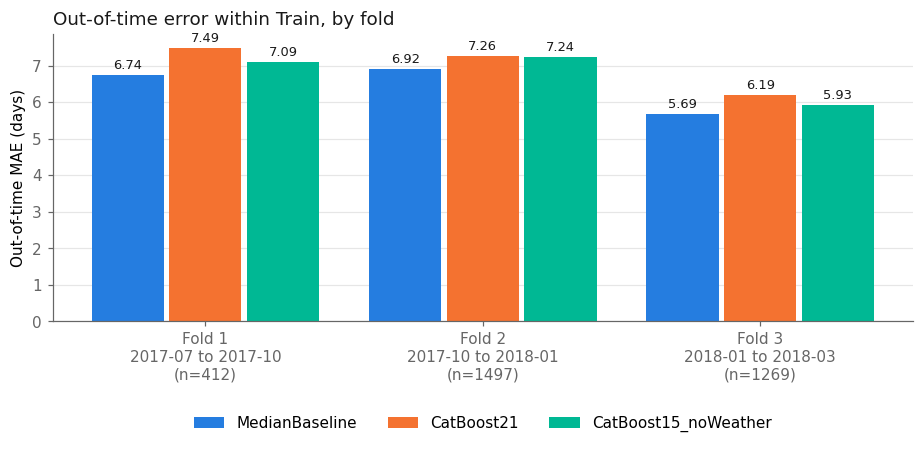

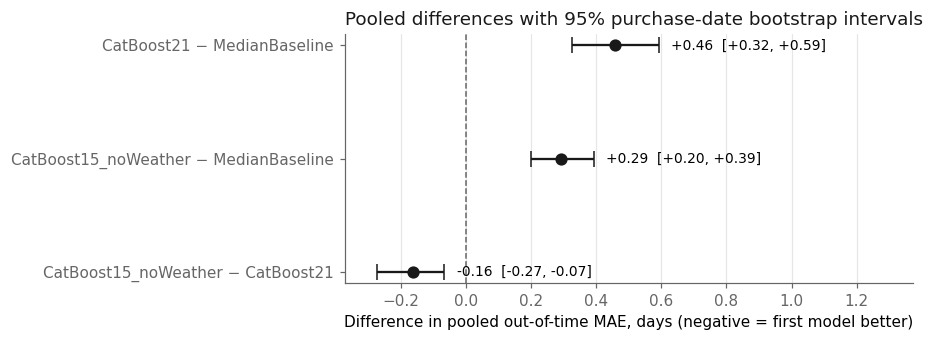

In [7]:
def style(ax, axis='y'):
    ax.grid(axis=axis, color='#e6e6e6', linewidth=0.8)
    ax.set_axisbelow(True)

# Figure 1: out-of-time MAE by fold, with values labelled on every bar.
fig, ax = plt.subplots(figsize=(8.5, 4.4))
pivot = fold_metrics.pivot(index='fold', columns='model', values='out_of_time_MAE')[CONFIGS]
n = fold_metrics.drop_duplicates('fold').set_index('fold').score_orders
x = np.arange(len(pivot)); width = 0.26
for i, name in enumerate(CONFIGS):
    bars = ax.bar(x + (i - 1) * (width + 0.02), pivot[name], width, color=COLORS[name], label=name)
    ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=8.5, color='#191919')
labels = [f'{f.replace("_", " ").title()}\n{s[:7]} to {e[:7]}\n(n={n[f]})' for f, s, e in FOLDS]
ax.set_xticks(x, labels)
ax.set_ylabel('Out-of-time MAE (days)')
ax.set_title('Out-of-time error within Train, by fold', loc='left', color='#191919')
ax.legend(frameon=False, ncols=3, loc='upper center', bbox_to_anchor=(0.5, -0.28))
style(ax); fig.tight_layout()
fig.savefig(FIGURES / 'out_of_time_mae_by_fold.png', dpi=180, bbox_inches='tight')
plt.show(); plt.close(fig)

# Figure 2: pooled differences with 95% intervals.
fig, ax = plt.subplots(figsize=(8.5, 3.2))
for i, row in differences.iloc[::-1].reset_index(drop=True).iterrows():
    ax.errorbar(row.difference, i, xerr=[[row.difference - row.ci95_low], [row.ci95_high - row.difference]],
                fmt='o', color='#191919', capsize=5, markersize=7, linewidth=1.5)
    ax.annotate(f'{row.difference:+.2f}  [{row.ci95_low:+.2f}, {row.ci95_high:+.2f}]',
                (row.ci95_high, i), xytext=(8, 0), textcoords='offset points', va='center', fontsize=9)
ax.axvline(0, color='#666666', linewidth=1, linestyle='--')
ax.set_yticks(range(len(differences)), differences.comparison.iloc[::-1].str.replace(' minus ', ' − '))
ax.set_xlabel('Difference in pooled out-of-time MAE, days (negative = first model better)')
ax.set_title('Pooled differences with 95% purchase-date bootstrap intervals', loc='left', color='#191919')
lo = differences.ci95_low.min(); hi = differences.ci95_high.max()
ax.set_xlim(min(lo, 0) - 0.1, hi + (hi - min(lo, 0)) * 0.9)
style(ax, 'x'); fig.tight_layout()
fig.savefig(FIGURES / 'pooled_differences_ci.png', dpi=180, bbox_inches='tight')
plt.show(); plt.close(fig)

## 7. Reading the diagnostics against the declared rules

In [8]:
d = differences.set_index('comparison')
h1 = d.loc['CatBoost21 minus MedianBaseline']
h2 = d.loc['CatBoost15_noWeather minus CatBoost21']
gain = pooled.set_index('model').in_sample_gain_vs_baseline_mean
fp = fingerprint_table.iloc[1]
h1_supported = bool(h1.ci95_high >= 0)
h2_parts = {'fingerprint': fp.orders_whose_vector_is_one_date_pct >= 90,
            'larger_in_sample_gain_with_weather': gain['CatBoost21'] > gain['CatBoost15_noWeather'],
            'no_worse_without_weather': h2.difference <= 0}
summary = {'H1_supported': h1_supported, 'H2_criteria': {k: bool(v) for k, v in h2_parts.items()},
           'H2_supported': bool(all(h2_parts.values())),
           'catboost21_minus_baseline': [h1.difference, h1.ci95_low, h1.ci95_high],
           'noweather_minus_catboost21': [h2.difference, h2.ci95_low, h2.ci95_high],
           'validation_or_test_scored': False}
(TABLES / 'diagnostic_summary.json').write_text(json.dumps(summary, indent=2, default=float), encoding='utf-8')
display(Markdown(f'''
- **H1 (weak transferable signal):** CatBoost21 − baseline = {h1.difference:+.2f} days [{h1.ci95_low:+.2f}, {h1.ci95_high:+.2f}] → {'supported' if h1_supported else 'not supported'}.
- **H2 (weather as date fingerprint):** {fp.orders_whose_vector_is_one_date_pct:.1f}% of Train orders have a state-weather vector seen on only one purchase date; mean in-sample gain over the baseline is {gain['CatBoost21']:.2f} days with weather and {gain['CatBoost15_noWeather']:.2f} without; removing weather changes out-of-time MAE by {h2.difference:+.2f} days [{h2.ci95_low:+.2f}, {h2.ci95_high:+.2f}] → {'supported' if summary['H2_supported'] else 'not fully supported'} ({', '.join(k for k, v in h2_parts.items() if not v) or 'all three criteria met'}{' failed' if not summary['H2_supported'] else ''}).
'''))


- **H1 (weak transferable signal):** CatBoost21 − baseline = +0.46 days [+0.32, +0.59] → supported.
- **H2 (weather as date fingerprint):** 100.0% of Train orders have a state-weather vector seen on only one purchase date; mean in-sample gain over the baseline is 1.89 days with weather and 1.45 without; removing weather changes out-of-time MAE by -0.16 days [-0.27, -0.07] → supported (all three criteria met).


### Limits of this diagnostic

- Folds are small, especially fold 1 (fit on a few hundred orders), and all periods were already inspected in EDA.
- The fit sets exclude long delays still pending at each fold start, mirroring the main design's label rule.
- A better configuration found here is **not** a validated model: the validation periods have been used, and any new candidate would need a fresh, separately declared evaluation.